# network intrusion detection with NSL-KDD

## 1. what i wanted to find out

a 10 GB rule would flag a scheduled 20 GB backup every night and miss a malicious 8 GB transfer. rules are useful for known signatures. here i wanted to see if the service, duration and byte counts together could help pick which connections to investigate.

each row describes one connection. the model returns 0 for normal or 1 for malicious. an analyst would review the flagged connections.

## 2. check the data

i used the training and test files from the provided split. the README has the download links. first i checked the columns, missing values and duplicate rows.

In [1]:
%matplotlib inline

from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path("..") if Path.cwd().name == "deliverables" else Path(".")
DATA = ROOT / "data"
FIGURES = ROOT / "deliverables"
FIGURES.mkdir(parents=True, exist_ok=True)

FEATURES = 'duration protocol_type service flag src_bytes dst_bytes land wrong_fragment urgent hot num_failed_logins logged_in num_compromised root_shell su_attempted num_root num_file_creations num_shells num_access_files num_outbound_cmds is_host_login is_guest_login count srv_count serror_rate srv_serror_rate rerror_rate srv_rerror_rate same_srv_rate diff_srv_rate srv_diff_host_rate dst_host_count dst_host_srv_count dst_host_same_srv_rate dst_host_diff_srv_rate dst_host_same_src_port_rate dst_host_srv_diff_host_rate dst_host_serror_rate dst_host_srv_serror_rate dst_host_rerror_rate dst_host_srv_rerror_rate'.split()
CATEGORICAL = ["protocol_type", "service", "flag"]
NUMERIC = [name for name in FEATURES if name not in CATEGORICAL]


def load_split(filename):
    frame = pd.read_csv(DATA / filename, header=None)
    if frame.shape[1] != len(FEATURES) + 2:
        raise ValueError(f"Unexpected column count in {filename}: {frame.shape[1]}")
    frame.columns = [*FEATURES, "label", "difficulty"]
    if frame.isna().any().any() or not np.isfinite(frame[NUMERIC]).all().all():
        raise ValueError(f"Missing or non-finite values in {filename}")
    return frame


train = load_split("KDDTrain+.txt")
test = load_split("KDDTest+.txt")
for name, frame in (("Train", train), ("Test", test)):
    print(f"{name}: {frame.shape}, {frame.duplicated().sum()} duplicate full rows")
print("Training label examples:", ", ".join(train["label"].value_counts().head().index))
display(train[["protocol_type", "service", "duration", "src_bytes", "label"]].head())

Train: (125973, 43), 0 duplicate full rows
Test: (22544, 43), 0 duplicate full rows
Training label examples: normal, neptune, satan, ipsweep, portsweep


,protocol_type,service,duration,src_bytes,label
0,tcp,ftp_data,0,491,normal
1,udp,other,0,146,normal
2,tcp,private,0,0,neptune
3,tcp,http,0,232,normal
4,tcp,http,0,199,normal


## 3. prepare the inputs

i kept the 41 measured features and removed the label and difficulty score from the inputs. there were no missing values to fill. normal is 0 and every attack label is 1.

i used one indicator per category and scaled the numeric columns. the pipeline learns the categories and scales from the training file. if a category only shows up at test time, its indicators are all zero.

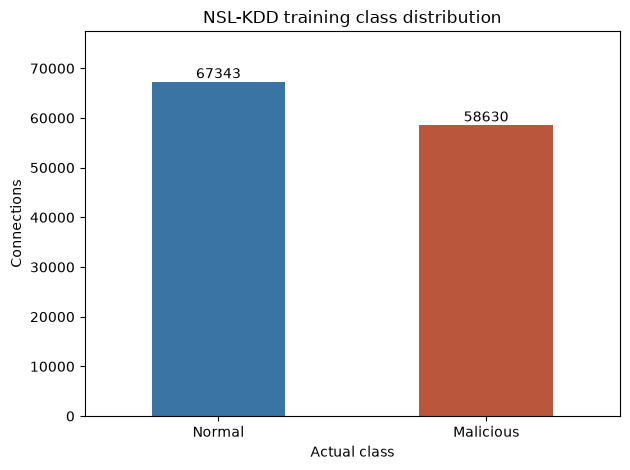

In [2]:
X_train = train[FEATURES]
X_test = test[FEATURES]
y_train = train["label"].ne("normal").astype(int)
y_test = test["label"].ne("normal").astype(int)

counts = y_train.value_counts().reindex([0, 1])
counts.index = ["Normal", "Malicious"]
ax = counts.plot.bar(rot=0, title="NSL-KDD training class distribution", color=["#3974a4", "#ba563c"])
ax.set(xlabel="Actual class", ylabel="Connections")
ax.bar_label(ax.containers[0], fmt="%d")
ax.set_ylim(0, counts.max() * 1.15)
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "training-class-distribution.png", dpi=150)
plt.show()

preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

## 4. fit the models

the baseline always picks the most common training label. logistic regression learns a weight for each feature and uses a sigmoid to turn the combined score into a probability. the cutoff is 0.5. the scikit-learn time below includes preprocessing.

In [3]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

logistic = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000)),
])
started = perf_counter()
logistic.fit(X_train, y_train)
print(f"Scikit-learn fit with preprocessing: {perf_counter() - started:.3f} s")
print("Solver iterations:", logistic["classifier"].n_iter_.tolist())

Scikit-learn fit with preprocessing: 4.127 s
Solver iterations: [159]


## 5. check the test results

precision tells me how many of the alerts were correct. recall tells me how many malicious connections the model caught. F1 combines the two. accuracy counts correct predictions across both classes. the baseline raises no alerts, so its undefined precision is shown as zero.

,Accuracy,Precision,Recall,F1
Majority baseline,0.4308,0.0000,0.0000,0.0000
Scikit-learn logistic regression,0.7537,0.9175,0.6233,0.7423


True negatives: 8,992 | False positives: 719
False negatives: 4,834 | True positives: 7,999


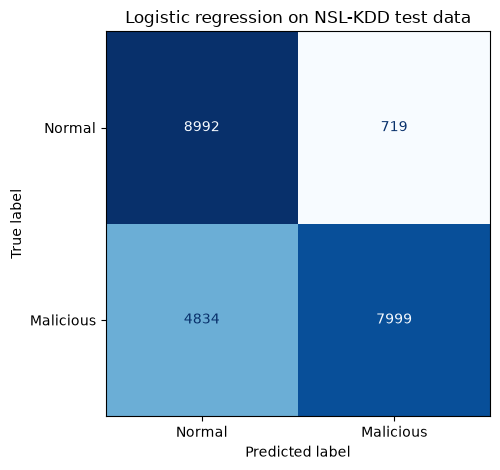

In [4]:
def score(y_true, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, predicted, average="binary", zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


baseline_predictions = baseline.predict(X_test)
logistic_predictions = logistic.predict(X_test)
results = pd.DataFrame.from_dict(
    {
        "Majority baseline": score(y_test, baseline_predictions),
        "Scikit-learn logistic regression": score(y_test, logistic_predictions),
    },
    orient="index",
)
display(results.round(4))

matrix = confusion_matrix(y_test, logistic_predictions, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
assert matrix.sum() == len(y_test)
assert np.isclose(tp / (tp + fn), results.loc["Scikit-learn logistic regression", "Recall"])
print(f"True negatives: {tn:,} | False positives: {fp:,}")
print(f"False negatives: {fn:,} | True positives: {tp:,}")

chart = ConfusionMatrixDisplay(matrix, display_labels=["Normal", "Malicious"])
chart.plot(cmap="Blues", values_format="d", colorbar=False)
chart.ax_.set_title("Logistic regression on NSL-KDD test data")
chart.figure_.tight_layout()
chart.figure_.savefig(FIGURES / "test-confusion-matrix.png", dpi=150)
plt.show()

## 6. try the same setup in PyTorch

the optional `torch` dependency group runs this cell. i reused the prepared features and kept one linear output. the loop computes the score and loss, then uses the gradients to update the weights. PyTorch uses a different optimizer and regularization here. its timer starts after the data is ready.

In [5]:
import importlib.util

if importlib.util.find_spec("torch") is None:
    print("PyTorch comparison skipped. Run with uv run --group torch to enable it.")
else:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset

    torch.manual_seed(42)
    torch.set_num_threads(2)

    def to_tensor(frame):
        values = logistic["preprocess"].transform(frame)
        if hasattr(values, "toarray"):
            values = values.toarray()
        return torch.as_tensor(values, dtype=torch.float32)

    train_features = to_tensor(X_train)
    test_features = to_tensor(X_test)
    train_labels = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
    batches = DataLoader(
        TensorDataset(train_features, train_labels), batch_size=1024, shuffle=True
    )

    linear_model = nn.Linear(train_features.shape[1], 1)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(linear_model.parameters(), lr=0.01)
    started = perf_counter()
    for epoch in range(10):
        loss_sum = 0.0
        for features, labels in batches:
            optimizer.zero_grad()
            logits = linear_model(features).squeeze(1)
            loss = loss_fn(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(labels)
        if epoch in (0, 4, 9):
            print(f"Epoch {epoch + 1}: mean training loss {loss_sum / len(train_labels):.4f}")
    print(f"PyTorch CPU training after preprocessing: {perf_counter() - started:.3f} s")

    linear_model.eval()
    with torch.inference_mode():
        probabilities = linear_model(test_features).squeeze(1).sigmoid()
        torch_predictions = (probabilities >= 0.5).int().numpy()
    results.loc["PyTorch linear classifier"] = score(y_test, torch_predictions)
    display(results.round(4))

Epoch 1: mean training loss 0.1840


Epoch 5: mean training loss 0.0844


Epoch 10: mean training loss 0.0762
PyTorch CPU training after preprocessing: 4.992 s


,Accuracy,Precision,Recall,F1
Majority baseline,0.4308,0.0000,0.0000,0.0000
Scikit-learn logistic regression,0.7537,0.9175,0.6233,0.7423
PyTorch linear classifier,0.7523,0.9180,0.6203,0.7403


## 7. what i'd check before deployment

719 false alarms would take time to review. 4,834 malicious connections would have no alert from the scikit-learn model. those numbers come from an older benchmark, so i'd check how the model behaves on recent traffic before relying on it.

i'd start by sending alerts to the SIEM for review. i'd check which features the sensor can provide and track how alert quality changes over time. i'd verify uncertain alerts against another source and measure scoring time, backlog and lost records when traffic picks up.